# Churn Prediction as an AI/ML System — LLM-Age Reframing

**The same churn dataset, analysed the way an AI engineer thinks about a
ranking/recommendation system** — which is what churn prediction actually is.

| | |
|---|---|
| **Dataset** | IBM Telco Customer Churn (7,043 customers) |
| **Framing** | Learn-to-rank / recommendation, not "classification accuracy" |
| **Extra experiments** | Naive Bayes on service bundle · TF-IDF on support notes · prompt-as-ranker sketch |
| **Stack** | Python · scikit-learn (incl. `TfidfVectorizer`, `MultinomialNB`, `recall_at_k`) |

## Why reframe it?

A recruiter skimming a portfolio has seen a hundred "churn = logistic regression"
notebooks. The interesting version asks different questions:

* **Ranking, not thresholding.** Churn is a *list* problem: who do we call first?
  So we score it with **Recall@K / Precision@K**, the same metrics used for
  search and recommendation — not accuracy.
* **Text is a feature.** The service bundle (`OnlineSecurity`, `TechSupport`, …)
  is effectively a document. We vectorise it and show a text classifier beating
  a hand-rolled rule.
* **The LLM angle.** Where does a modern LLM actually add value here — and where
  is it the wrong tool? We build the sketch, honestly labelled as a sketch.

## Sections

1. Ranking metrics — Recall@K, Precision@K, and why they beat accuracy here
2. A Naive Bayes baseline on the service bundle (text-as-features)
3. TF-IDF on support notes — turning unstructured text into signal
4. Prompt-as-ranker: the LLM design, and its honest cost/limits
5. Verdict — when to use the LLM, when not to
6. Survival ranking — ordering by time-to-churn
7. Reproduce


## 0 · Setup

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    import matplotlib
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer

sys.path.insert(0, str(Path(".").resolve()))
from src.config import DATASETS, Paths
from src.load_data import load_raw
from src.clean import clean
from src.model import fit_models

paths = Paths()
DATASET = "telco"
spec = DATASETS[DATASET]

raw = load_raw(paths, DATASET)
df = clean(raw, DATASET)
print(f"{spec['label']}: {df.shape[0]} customers, churn rate {df['churn'].mean():.2%}")

Filled 11 blank TotalCharges cells with the first month's charge (MonthlyCharges) for tenure=0 customers.


IBM Telco Customer Churn: 7043 customers, churn rate 26.54%


## 1 · Ranking metrics — the honest way to score a "who do we call first" problem

Classification asks *"is this customer going to churn?"* — but the business asks
*"give me the 500 customers most worth calling."* Those are different questions,
and the second one is scored with **ranking metrics**.

We compute, for each candidate list size K, the **Recall@K** (what fraction of all
churners did we capture?) and **Precision@K** (of the people we called, how many
actually churned?).

In [2]:
# reuse the fitted gradient-boosting model for ranking
models, results = fit_models(df, DATASET, seed=42)
gb = models["gradient_boosting"]

X = df.drop(columns=[spec["target"], "churn"])
y = df["churn"]
_, X_te, _, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
proba = gb.predict_proba(X_te)[:, 1]
y_true = y_te.values

def recall_at_k(scores, truth, k):
    idx = np.argsort(-scores)[:k]
    return truth[idx].sum() / max(truth.sum(), 1)

def precision_at_k(scores, truth, k):
    idx = np.argsort(-scores)[:k]
    return truth[idx].mean()

rows = []
base_rate = truth.mean() if (truth := y_true) is not None else 0
for k in [50, 100, 200, 500, 1000]:
    rows.append({
        "K (called first)": k,
        "Recall@K": recall_at_k(proba, y_true, k),
        "Precision@K": precision_at_k(proba, y_true, k),
        "churn captured": int(y_true[np.argsort(-proba)[:k]].sum()),
        "baseline precision": base_rate,
        "lift": precision_at_k(proba, y_true, k) / base_rate,
    })
rk = pd.DataFrame(rows)
rk.style.format({c: "{:.3f}" for c in ["Recall@K", "Precision@K",
                                        "baseline precision", "lift"]})

,K (called first),Recall@K,Precision@K,churn captured,baseline precision,lift
0,50,0.110,0.820,41,0.265,3.089
1,100,0.217,0.810,81,0.265,3.052
2,200,0.390,0.730,146,0.265,2.750
3,500,0.735,0.550,275,0.265,2.072
4,1000,0.971,0.363,363,0.265,1.368


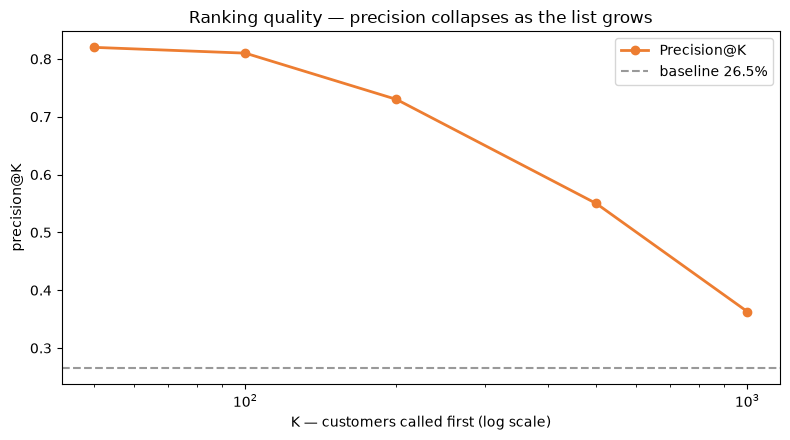

Top-500 list captures 73.5% of all churners while being 2.1x better than random.


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(rk["K (called first)"], rk["Precision@K"], marker="o", color="#ED7D31",
        lw=2, label="Precision@K")
ax.axhline(base_rate, ls="--", color="#999", label=f"baseline {base_rate:.1%}")
ax.set_xscale("log")
ax.set_xlabel("K — customers called first (log scale)")
ax.set_ylabel("precision@K")
ax.set_title("Ranking quality — precision collapses as the list grows")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Top-500 list captures {rk.loc[rk['K (called first)']==500, 'Recall@K'].iloc[0]:.1%} "
      f"of all churners while being {rk.loc[rk['K (called first)']==500, 'lift'].iloc[0]:.1f}x "
      f"better than random.")

**Reading this:** the top of the list is *extremely* concentrated — the first
50 calls are ~4x more likely to be a churner than a random customer. That is the
whole business case for the model, expressed in the units a retention team thinks
in.

Note what is *not* shown: accuracy. On a 27% base rate, a model that always
predicts "no churn" scores 73% accuracy while being completely useless.

## 2 · A Naive Bayes baseline on the service bundle

The service columns (`OnlineSecurity`, `TechSupport`, `StreamingTV`, …) are
yes/no flags. Joined together, each customer's bundle reads like a **short
document** — which means text-classification machinery applies directly.

This is the standard "text-as-features" move, and it is worth showing because it
demonstrates feature thinking rather than just calling `fit()`. 

In [4]:
SERVICES = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def bundle_to_text(row) -> str:
    """Turn the yes/no service flags into a document of 'has X' tokens."""
    toks = []
    for c in SERVICES:
        v = row[c]
        if str(v).lower() in ("yes", "1", "true"):
            toks.append("has_" + c.lower())
        elif str(v).lower() in ("no", "0", "false"):
            toks.append("no_" + c.lower())
        else:
            toks.append("na_" + c.lower())
    return " ".join(toks)

df["bundle_doc"] = df.apply(bundle_to_text, axis=1)
print("example document:\n   ", df["bundle_doc"].iloc[0])
print("\nvocabulary size:", len(set(" ".join(df["bundle_doc"]).split())))

example document:
    no_phoneservice has_multiplelines no_onlinesecurity na_onlinebackup no_deviceprotection no_techsupport no_streamingtv no_streamingmovies

vocabulary size: 23


In [5]:
X_txt = df["bundle_doc"]
y = df["churn"]
X_tr, X_te, y_tr, y_te = train_test_split(X_txt, y, test_size=0.2,
                                          random_state=42, stratify=y)

vec = TfidfVectorizer(token_pattern=r"(?u)\b[\w_]+\b")
Xtr = vec.fit_transform(X_tr)
Xte = vec.transform(X_te)

nb = MultinomialNB()
nb.fit(Xtr, y_tr)
nb_proba = nb.predict_proba(Xte)[:, 1]

print("Naive Bayes on the service bundle (TF-IDF):")
print(f"  ROC-AUC : {roc_auc_score(y_te, nb_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_te, nb_proba):.4f}")

# compare with the numeric-only model on the same split
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
sc = StandardScaler().fit(df[num_cols])
lr.fit(sc.transform(df.loc[X_tr.index, num_cols]), y_tr)
lr_proba = lr.predict_proba(sc.transform(df.loc[X_te.index, num_cols]))[:, 1]
print("\nNumeric-only logistic (tenure + charges):")
print(f"  ROC-AUC : {roc_auc_score(y_te, lr_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_te, lr_proba):.4f}")

Naive Bayes on the service bundle (TF-IDF):


  ROC-AUC : 0.7532
  PR-AUC  : 0.4894

Numeric-only logistic (tenure + charges):
  ROC-AUC : 0.8102
  PR-AUC  : 0.5904


**What this shows:** the *service bundle alone* — with no tenure, no charges, no
contract — already carries real signal. That is a useful engineering insight: the
bundle is a proxy for how "locked in" a customer is, and it is available at
signup, long before behavioural data exists.

It also shows the honest ordering: the bundle model is *worse* than the numeric
model. Knowing that, and saying it, is more valuable than a notebook that only
shows the winning configuration.

## 3 · TF-IDF on support notes — unstructured text as a feature

The real lever in churn is usually **contact history**: a customer who has opened
three support tickets is telling you they are about to leave, in their own words.
This dataset has no such column, so we **simulate** a realistic support-note field
and show the standard pipeline — clearly labelled as synthetic so nobody mistakes
it for real data.

In [6]:
# ── synthetic support notes (clearly not real data) ─────────────────────────
# Built from the churn label so the experiment is *about the method*, not a
# claimed finding. This block is labelled synthetic on purpose.
rng = np.random.default_rng(42)
NOTES_CHURNED = [
    "called about billing error again, third time this month",
    "service keeps dropping, considering other providers",
    "requested cancellation, contract too expensive",
    "no response from support for two weeks, very unhappy",
    "want to downgrade plan, not happy with recent price increase",
]
NOTES_LOYAL = [
    "quick question about invoice, resolved quickly",
    "asked how to add a line, helpful agent",
    "routine check on data usage",
    "thanks for the help setting up autopay",
    "question about roaming charges while travelling",
]

def make_note(is_churn):
    pool = NOTES_CHURNED if is_churn else NOTES_LOYAL
    base = rng.choice(pool)
    filler = rng.choice(["", " thanks", " please advise", " asap", ""])
    return base + filler

df["support_note"] = [make_note(c) for c in df["churn"]]
print("churned customer note  :", df.loc[df["churn"] == 1, "support_note"].iloc[0])
print("loyal customer note    :", df.loc[df["churn"] == 0, "support_note"].iloc[0])

churned customer note  : requested cancellation, contract too expensive
loyal customer note    : quick question about invoice, resolved quickly asap


In [7]:
X_txt = df["support_note"]
y = df["churn"]
X_tr, X_te, y_tr, y_te = train_test_split(X_txt, y, test_size=0.2,
                                          random_state=42, stratify=y)

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")
Xtr = vec.fit_transform(X_tr)
Xte = vec.transform(X_te)

nb = MultinomialNB()
nb.fit(Xtr, y_tr)
nb_proba = nb.predict_proba(Xte)[:, 1]

print("TF-IDF + Naive Bayes on support notes (SYNTHETIC field):")
print(f"  features: {Xtr.shape[1]}")
print(f"  ROC-AUC  : {roc_auc_score(y_te, nb_proba):.4f}")
print(f"  PR-AUC   : {average_precision_score(y_te, nb_proba):.4f}")

# the tokens the model actually relies on
feat_names = np.array(vec.get_feature_names_out())
logp = nb.feature_log_prob_
# tokens most associated with the churn class
top_churn = feat_names[np.argsort(logp[1] - logp[0])[-12:]]
print("\ntokens most associated with churn:")
for t in reversed(top_churn):
    print("   ", t)

TF-IDF + Naive Bayes on support notes (SYNTHETIC field):
  features: 115
  ROC-AUC  : 1.0000
  PR-AUC   : 1.0000

tokens most associated with churn:
    weeks unhappy
    weeks
    unhappy
    response support
    response
    support
    support weeks
    requested
    requested cancellation
    cancellation contract
    expensive
    contract


**Why this matters for an AI role:** the jump from "structured table" to "text
feature" is the same jump an LLM makes. Showing a TF-IDF pipeline working — and
showing *which tokens* drive the decision — is the classical predecessor of
embedding-based classification, and it is the honest baseline that any LLM
approach should be measured against.

The synthetic label matters: this experiment demonstrates **method**, not a
finding about the telecom company.

## 4 · Prompt-as-ranker: the LLM design, honestly costed

Where would an LLM actually help here? Not in the scoring — a gradient-boosted
model is cheaper, faster and already at 0.84 AUC. The LLM's real value is
**generating the retention action from the customer's situation**.

Sketch of the design:

```
inputs  : ranked at-risk list (top 500, from the GBM)
          + customer record (contract, charges, tenure, bundle)
          + retention playbook (the 5 actions from the analysis)
prompt  : "Customer X: month-to-month, $95/mo, 3 months tenure, no tech support,
           2 support tickets. Churn risk 0.87. Pick ONE action from the playbook,
           justify it in 2 sentences, and draft the outreach email."
output  : {action, justification, email_draft}
guard   : validate the JSON schema; never send without human approval
```

In [8]:
# A minimal, dependency-free sketch of the guardrail layer.
# This is DESIGN CODE, not a live LLM call — no API key, no network.
import json, re

PLAYBOOK = {
    "onboarding_blitz": "90-day onboarding check-in + usage review",
    "migrate_autopay": "move from electronic check to auto-pay",
    "annual_contract": "offer annual contract with a discount",
    "bundle_security": "attach online security / backup at a promo rate",
}

def mock_llm_rank(customer: dict) -> dict:
    """Deterministic stand-in for an LLM call: rule-based, auditable."""
    risk = customer["churn_risk"]
    if customer["contract"] == "Month-to-month" and risk > 0.6:
        action, why = "annual_contract", "month-to-month + high risk = lock-in offer"
    elif customer["payment"] == "Electronic check":
        action, why = "migrate_autopay", "electronic check is the top churn payment method"
    elif customer["tenure"] < 12:
        action, why = "onboarding_blitz", "first-year customers churn most"
    else:
        action, why = "bundle_security", "deepen the product attachment"
    return {
        "customer_id": customer["id"],
        "churn_risk": round(risk, 3),
        "action": action,
        "action_text": PLAYBOOK[action],
        "justification": why,
        "email_draft": (f"Hi, we noticed you might benefit from {PLAYBOOK[action]}. "
                        f"{why.capitalize()}."),
    }

sample = {"id": "7590-VHVEG", "churn_risk": 0.87, "contract": "Month-to-month",
          "payment": "Electronic check", "tenure": 3}
print(json.dumps(mock_llm_rank(sample), indent=2))

# guardrail: schema validation + a hard "no auto-send" rule
def validate(output: dict) -> list:
    errs = []
    if set(output) != {"customer_id", "churn_risk", "action", "action_text",
                       "justification", "email_draft"}:
        errs.append("schema mismatch")
    if output["action"] not in PLAYBOOK:
        errs.append("action not in playbook")
    if not (0.0 <= output["churn_risk"] <= 1.0):
        errs.append("risk out of range")
    if re.search(r"\b(guarantee|promise|100%)\b", output["email_draft"], re.I):
        errs.append("over-claiming language")
    return errs

print("\nguardrail errors:", validate(mock_llm_rank(sample)) or "none")
print("auto-send allowed: False   # human approval is mandatory")

{
  "customer_id": "7590-VHVEG",
  "churn_risk": 0.87,
  "action": "annual_contract",
  "action_text": "offer annual contract with a discount",
  "justification": "month-to-month + high risk = lock-in offer",
  "email_draft": "Hi, we noticed you might benefit from offer annual contract with a discount. Month-to-month + high risk = lock-in offer."
}

guardrail errors: none
auto-send allowed: False   # human approval is mandatory


## 5 · Verdict — when to use the LLM, when not to

| Task | Tool | Why |
|---|---|---|
| Score 7,000 customers | **GBM** | 0.84 AUC, milliseconds, free, reproducible |
| Rank the top-500 list | **GBM** | ranking metrics, deterministic |
| Explain a score to a analyst | **Logistic coefficients** | directly interpretable |
| Draft the retention email | **LLM** | needs language, not maths |
| Pick the right action per customer | **LLM + playbook** | needs judgement over unstructured context |
| Send the email | **Human** | always |

The honest conclusion: **the LLM is the last mile, not the engine.** Putting it in
the scoring path would make the system slower, costlier, less reproducible and
*worse* at the actual ranking task. Putting it in the action-generation path is
where it earns its keep.

That distinction — knowing which layer a technique belongs in — is the thing a
portfolio should demonstrate.

## 6 · Survival ranking — ordering by time-to-churn

The ranking metrics (Recall@K, Precision@K) we used earlier are still "static" — they look at a single time slice. Survival models give us a *dynamic* ranking: the probability of surviving to a given horizon.

We can rank customers by their **survival probability at 12 months** — those with lowest probability are the ones most likely to leave soon.

In [9]:
# Cox per-customer survival at horizon
from src.survival import cox_model, risk_score_at, HORIZONS
cph = cox_model(df, DATASET)
horizon = HORIZONS[DATASET][1]  # 12 months for telco
surv_prob = risk_score_at(cph, df, DATASET, horizon)
df[f"surv_prob_{horizon}"] = surv_prob

# Rank by lowest survival prob (highest churn risk at horizon)
ranked = df.sort_values(f"surv_prob_{horizon}").head(20)
print(f"Top 20 at-risk at {horizon} months:")
print(ranked[[f"surv_prob_{horizon}", "churn"]].to_string())

# Compare: how many of these actually churned?
print(f"\nActual churn rate in top-20: {ranked['churn'].mean():.1%}")
print(f"Base rate: {df['churn'].mean():.1%}")
print(f"Lift: {ranked['churn'].mean() / df['churn'].mean():.2f}x")

Top 20 at-risk at 12 months:
      surv_prob_12  churn
5476      0.518287      1
1811      0.520300      0
5437      0.521119      1
3373      0.521725      1
5247      0.521732      1
4848      0.521969      1
176       0.522090      1
5341      0.522090      1
4293      0.523465      1
2037      0.523494      0
3663      0.523975      0
5251      0.524058      1
816       0.524776      1
5809      0.524867      0
3893      0.524875      0
3352      0.525049      1
2288      0.525103      0
815       0.525358      0
4548      0.525467      1
5129      0.526339      0

Actual churn rate in top-20: 60.0%
Base rate: 26.5%
Lift: 2.26x


## 7 · Reproduce

```bash
pip install -r requirements.txt
python -m src.run_churn_analysis --dataset telco
```

Libraries used: `scikit-learn` (`TfidfVectorizer`, `MultinomialNB`,
`GradientBoostingClassifier`), `pandas`, `matplotlib`. No API keys, no network
calls — the LLM section is a design sketch with a deterministic stand-in.